In [1]:
import pandas as pd
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

sys.path.insert(0, str(Path("../postprocessing").resolve()))
from conversion_gpx import convert_gpx_to_csv

### Chargement des données

In [2]:
gpx_file = Path("Acquisition_4_48.gpx")
csv_gpx_output = Path("Acquisition_4_48.csv")

convert_gpx_to_csv(gpx_file, csv_gpx_output)

donnees_imu_gnss = pd.read_csv("synced_imu_gnss.csv")
donnees_strava = pd.read_csv(csv_gpx_output)

print("Données IMU/GNSS chargées :", donnees_imu_gnss.shape)
print("Données Strava chargées :", donnees_strava.shape)


Conversion terminée ! Fichier enregistré : Acquisition_4_48.csv
Données IMU/GNSS chargées : (537, 9)
Données Strava chargées : (522, 3)


### Aperçu des données

In [3]:
print("\n Les données IMU/GNSS ")
print(donnees_imu_gnss.head())


 Les données IMU/GNSS 
      timestamp   accel_x   accel_y   accel_z   gyro_x   gyro_y  gyro_z  \
0  1.778078e+09  0.915061  0.089121  0.111325  22.9950 -13.8600  8.6450   
1  1.778078e+09  1.012722  0.122732 -0.021533   1.4700   2.5900  2.1175   
2  1.778078e+09  1.119350 -0.010431  0.083692  -4.7775  11.9525 -2.8000   
3  1.778078e+09  0.907131 -0.082289  0.005856  26.4425   6.4225 -8.8200   
4  1.778078e+09  1.212924  0.069174  0.172142   6.5625  13.3000  4.0250   

     latitude  longitude  
0  177.384557   1.068485  
1   49.384563   1.068484  
2   49.384573   1.068478  
3   49.384584   1.068464  
4   49.384587   1.068439  


In [4]:
print("\n Les données Strava ")
print(donnees_strava.head())


 Les données Strava 
                     UTC   Latitude  Longitude
0  2026/05/06 - 14:39:05  49.384609   1.068483
1  2026/05/06 - 14:39:06  49.384622   1.068442
2  2026/05/06 - 14:39:07  49.384632   1.068414
3  2026/05/06 - 14:39:08  49.384642   1.068369
4  2026/05/06 - 14:39:09  49.384636   1.068416


### Nettoyage

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

imu = donnees_imu_gnss.copy()
strava = donnees_strava.copy()

imu = imu.rename(columns={
    "latitude": "Latitude",
    "longitude": "Longitude"
})

# On enlève les coordonnées impossibles
imu = imu[
    imu["Latitude"].between(-90, 90) &
    imu["Longitude"].between(-180, 180)
].copy()

# On garde les points IMU proches de la trajectoire Strava en definissant une marge
marge = 0.001

lat_min = strava["Latitude"].min() - marge
lat_max = strava["Latitude"].max() + marge
lon_min = strava["Longitude"].min() - marge
lon_max = strava["Longitude"].max() + marge

imu = imu[
    imu["Latitude"].between(lat_min, lat_max) &
    imu["Longitude"].between(lon_min, lon_max)
].copy()

print("Points IMU/GNSS gardés :", len(imu))
print("Points Strava gardés   :", len(strava))

Points IMU/GNSS gardés : 524
Points Strava gardés   : 522


### Comparaison des trajectoires

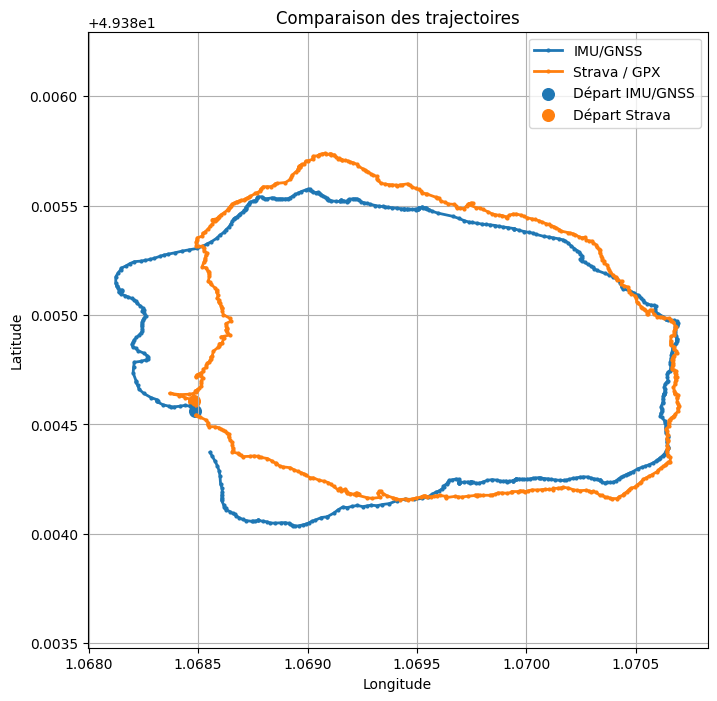

In [6]:
plt.figure(figsize=(8, 8))

plt.plot(
    imu["Longitude"],
    imu["Latitude"],
    label="IMU/GNSS",
    linewidth=2,
    marker="o",
    markersize=2
)

plt.plot(
    strava["Longitude"],
    strava["Latitude"],
    label="Strava / GPX",
    linewidth=2,
    marker="o",
    markersize=2
)

plt.scatter(imu["Longitude"].iloc[0], imu["Latitude"].iloc[0], s=70, label="Départ IMU/GNSS")
plt.scatter(strava["Longitude"].iloc[0], strava["Latitude"].iloc[0], s=70, label="Départ Strava")

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Comparaison des trajectoires")
plt.legend()
plt.grid(True)
plt.axis("equal")
plt.show()

### Ecart entre les trajectoires

In [24]:

imu["UTC"] = pd.to_datetime(
    imu["timestamp"], unit="s", utc=True
).astype("datetime64[ns, UTC]")

strava["UTC"] = pd.to_datetime(
    strava["UTC"], format="%Y/%m/%d - %H:%M:%S", utc=True
).astype("datetime64[ns, UTC]")

imu_cmp = imu[["UTC", "Latitude", "Longitude"]].sort_values("UTC").rename(columns={
    "Latitude": "Latitude_imu",
    "Longitude": "Longitude_imu"
})

strava_cmp = strava[["UTC", "Latitude", "Longitude"]].sort_values("UTC").rename(columns={
    "Latitude": "Latitude_strava",
    "Longitude": "Longitude_strava"
})

print(imu_cmp["UTC"].dtype)
print(strava_cmp["UTC"].dtype)

comparaison = pd.merge_asof(
    imu_cmp,
    strava_cmp,
    on="UTC",
    direction="nearest",
    tolerance=pd.Timedelta("1s")
).dropna()

R = 6371000

lat1 = np.radians(comparaison["Latitude_imu"])
lon1 = np.radians(comparaison["Longitude_imu"])
lat2 = np.radians(comparaison["Latitude_strava"])
lon2 = np.radians(comparaison["Longitude_strava"])

dlat = lat2 - lat1
dlon = lon2 - lon1

a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
angle = 2 * np.arctan2(np.sqrt(a), np.sqrt(1 - a))

comparaison["ecart_m"] = R * angle

print("Nombre de points comparés :", len(comparaison))
print(f"Ecart moyen  : {comparaison['ecart_m'].mean():.2f} m")
print(f"Ecart median : {comparaison['ecart_m'].median():.2f} m")
print(f"Ecart max    : {comparaison['ecart_m'].max():.2f} m")

comparaison.head()

datetime64[ns, UTC]
datetime64[ns, UTC]
Nombre de points comparés : 524
Ecart moyen  : 14.72 m
Ecart median : 14.30 m
Ecart max    : 34.69 m


,UTC,Latitude_imu,Longitude_imu,Latitude_strava,Longitude_strava,ecart_m
0,2026-05-06 14:39:09.419356108+00:00,49.384563,1.068484,49.384636,1.068416,9.502641
1,2026-05-06 14:39:10.447307110+00:00,49.384573,1.068478,49.384638,1.068460,7.364556
2,2026-05-06 14:39:11.477473259+00:00,49.384584,1.068464,49.384641,1.068476,6.429293
3,2026-05-06 14:39:12.402666092+00:00,49.384587,1.068439,49.384647,1.068489,7.640019
4,2026-05-06 14:39:13.538307905+00:00,49.384583,1.068415,49.384656,1.068495,9.971118


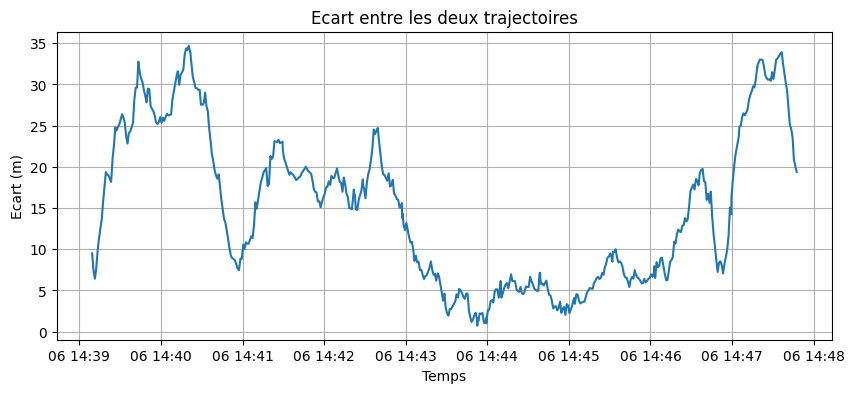

In [25]:

plt.figure(figsize=(10, 4))
plt.plot(comparaison["UTC"], comparaison["ecart_m"])
plt.xlabel("Temps")
plt.ylabel("Ecart (m)")
plt.title("Ecart entre les deux trajectoires")
plt.grid(True)
plt.show()

### # Histogramme des erreurs

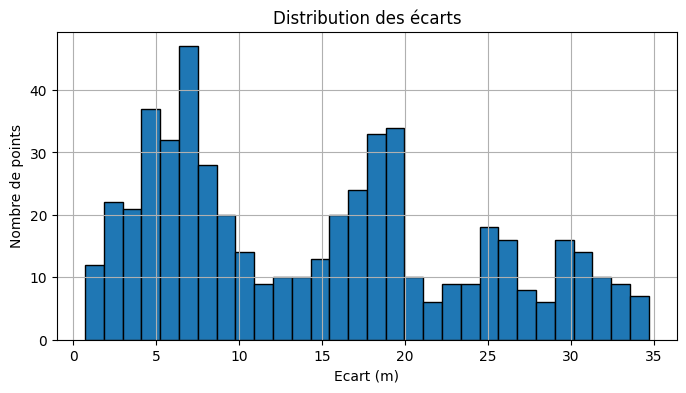

In [26]:
plt.figure(figsize=(8, 4))
plt.hist(comparaison["ecart_m"], bins=30, edgecolor="black")
plt.xlabel("Ecart (m)")
plt.ylabel("Nombre de points")
plt.title("Distribution des écarts")
plt.grid(True)
plt.show()

In [27]:
# Fonction pour calculer la distance totale parcourue
def distance_haversine(lat1, lon1, lat2, lon2):
    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)
    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    angle = 2 * np.arctan2(np.sqrt(a), np.sqrt(1 - a))
    return R * angle

In [28]:
# Distance totale IMU/GNSS
dist_imu = distance_haversine(
    imu["Latitude"].values[:-1],
    imu["Longitude"].values[:-1],
    imu["Latitude"].values[1:],
    imu["Longitude"].values[1:]
).sum()

# Distance totale Strava
dist_strava = distance_haversine(
    strava["Latitude"].values[:-1],
    strava["Longitude"].values[:-1],
    strava["Latitude"].values[1:],
    strava["Longitude"].values[1:]
).sum()

print(f"Distance totale IMU/GNSS : {dist_imu:.2f} m")
print(f"Distance totale Strava   : {dist_strava:.2f} m")
print(f"Ecart sur distance totale: {abs(dist_imu - dist_strava):.2f} m")


Distance totale IMU/GNSS : 600.65 m
Distance totale Strava   : 642.71 m
Ecart sur distance totale: 42.06 m
